In [2]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

#=== FOR NMMIPW ===#
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri, numpy2ri
from rpy2.robjects.conversion import localconverter
from rpy2.robjects.packages import importr
nmm = importr("NMMIPW")
#==================#

Error importing in API mode: ImportError('On Windows, cffi mode "ANY" is only "ABI".')
Trying to import in ABI mode.


In [3]:
eps_vals = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]

In [4]:
n = 2000
d = 3
kk = (1, 20)

In [5]:
dg = DataGenerator('Normal')

In [6]:
class IPW_Estimator:

    def __init__(self, k_range, criterion="bic", cov_type='uni_diag', n_init=5):
        self.gmm = GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)
        self.gmm_m0 = GaussianMixtureMAR(k_range=k_range, criterion=criterion, cov_type=cov_type, n_init=n_init)
        self.pm0 = 0
        
    def fit(self, X, M):
        # Estimate p(x)
        self.gmm.fit(X, M)
    
        # Estimate p(x|M=0)
        idx_m0 = M.sum(dim=1)==d
        self.gmm_m0.fit(X[idx_m0], M[idx_m0])

        # Estimate P(M=0)
        self.pm0 = ((M.sum(dim=1) == d).sum() / M.shape[0]).item()
    
    def evaluate(self, X):
        # Estimate P(M=0|x) = p(x|M=0) * P(M=0) / p(x)
        return torch.minimum((torch.exp(self.gmm_m0.log_prob_x(X)) * self.pm0 / torch.exp(self.gmm.log_prob_x(X)))[:,0], torch.tensor(1))
    

In [7]:
def eval_p0_true(X):
    U1, U2 = dg.latent_uniforms(X)
    G1 = torch.maximum(U1, dg.c)
    G2 = torch.maximum(U2, dg.c)
    return (G1+G2)/3

In [8]:
ro.r('''
predict_prop <- function(ps, newdata, pattern) {
  X <- as.matrix(newdata); M <- nrow(pattern)
  work_df <- c(); selection <- c(0)
  for (m in 2:M) {
    work_df <- cbind(work_df, cbind(1, X[, pattern[m, ] == 1]))
    selection <- c(selection, sum(pattern[m, ]) + 1)
  }
  selection <- cumsum(selection)
  NMMIPW:::prop_compute(para = ps$gamma_para, work_df = work_df,
                        R = rep(1, nrow(X)), selection = selection,
                        sigma_star = ps$sigma_star, pattern = pattern)
}
''')
predict_prop = ro.r["predict_prop"]

In [9]:
def est_ipw_quant(X_ipw, M_ipw, X_quant, M_quant):
    ipw_est = IPW_Estimator(k_range=kk)
    ipw_est.fit(X_ipw, M_ipw)
    
    p0_test = ipw_est.evaluate(Xtest)

    idx_m0 = M_quant.sum(dim=1)==d
    Xm0 = X_quant[idx_m0]
    Xm0_np = Xm0.detach().numpy()
    p0_train = ipw_est.evaluate(Xm0)
    quantile_p0 = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/p0_train.detach().numpy())

    return p0_test, p0_train, quantile_p0

-1.2838995485980937
tensor(0.0100, dtype=torch.float64)
tensor([[0., 1., 1.],
        [1., 1., 1.],
        [1., 0., 1.],
        ...,
        [1., 0., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])
[[ 0.72062884 -0.17027684 -1.80330251]
 [ 0.91033108  1.4863342   0.63935722]
 [ 2.42186752  0.74031971 -0.50576895]
 ...
 [-0.92240738 -0.61308657 -0.2641105 ]
 [-0.01759522  0.0454643  -1.09409825]
 [-0.83331606 -1.28767756 -0.07131646]]


NameError: name 'i' is not defined

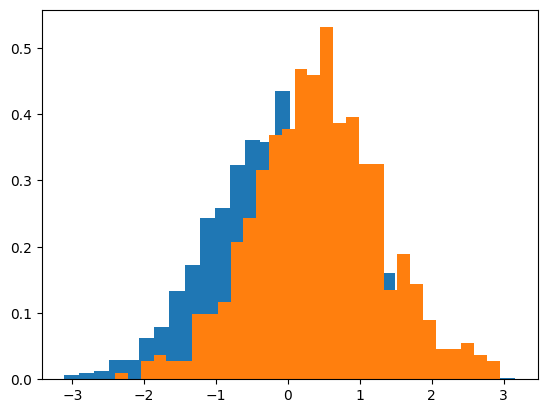

In [ ]:

B=1
n_test = int(n/2)
cross_fitting = False

quantile_unweighted = np.zeros(B)

p0_true_train = []
p0_true_test = np.zeros((B, n_test))
quantile_p0_true = np.zeros(B)

p0_nmmipw_train = []
p0_nmmipw_test = np.zeros((B, n_test))
quantile_p0_nmmipw = np.zeros(B)

p0_est_train = []
if cross_fitting:
    p0_est_test = np.zeros((B, 3, n_test))
    quantile_p0_est = np.zeros((B, 3))
else:
    p0_est_test = np.zeros((B, n_test))
    quantile_p0_est = np.zeros(B)



# Sample X, M
X = dg.sample_truth(n, d)
histogram = plt.hist(X[:,0].detach().numpy(), bins=30, density=True)
print(np.quantile(X[:,0], 0.1))
print(dg.c)
M = dg.generate_MNAR1(X, 0.0)
print(M)
# Ampute X accordingly
Xm = X.clone()
Xm[M == 0] = 0

# Determine unweighted quantile and that using the true IPW (on the whole dataset)
idx_m0 = M.sum(dim=1)==d

pattern = torch.tensor([1., 1., 1.], dtype=M.dtype, device=M.device)
idx_m0 = (M == pattern).all(dim=1) 


Xm0 = Xm[idx_m0]
histogram = plt.hist(Xm0[:,0].detach().numpy(), bins=30, density=True)

Xm0_np = Xm0.detach().numpy()
print(Xm0_np)
quantile_unweighted = np.quantile(Xm0_np[:,0], 0.1)
quantile_p0_true = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/eval_p0_true(Xm0).detach().numpy())

print("Unweighted quantile:", quantile_unweighted)

# evaluate P(M=0|x) on a test set for evaluation
Xtest = dg.sample_truth(n_test, d)
p0_true_test[i] = eval_p0_true(Xtest)
p0_true_train.append(eval_p0_true(Xm0))


print(Xm)


In [ ]:
X = dg.sample_truth(n, d)
M = dg.generate_MNAR1(X, 0.0)
# Ampute X accordingly
Xm = X.clone()
Xm[M == 0] = 0

print(M)
X

pattern = torch.tensor([0., 1., 1.], dtype=M.dtype, device=M.device)
mask = (M == pattern).all(dim=1)   # (N,) boolean: True where the row of M is [1, 0, 0]
X_sel = X[mask]                    # rows of X that correspond to those rows of M
X_sel

In [ ]:
B = 20
n_test = int(n/2)
cross_fitting = False

quantile_unweighted = np.zeros(B)

p0_true_train = []
p0_true_test = np.zeros((B, n_test))
quantile_p0_true = np.zeros(B)

p0_nmmipw_train = []
p0_nmmipw_test = np.zeros((B, n_test))
quantile_p0_nmmipw = np.zeros(B)

p0_est_train = []
if cross_fitting:
    p0_est_test = np.zeros((B, 3, n_test))
    quantile_p0_est = np.zeros((B, 3))
else:
    p0_est_test = np.zeros((B, n_test))
    quantile_p0_est = np.zeros(B)


for i in range(B):
    # Sample X, M
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, 0.0)
    # Ampute X accordingly
    Xm = X.clone()
    Xm[M == 0] = 0

    # Determine unweighted quantile and that using the true IPW (on the whole dataset)
    idx_m0 = M.sum(dim=1)==d
    Xm0 = Xm[idx_m0]
    Xm0_np = Xm0.detach().numpy()
    quantile_unweighted[i] = np.quantile(Xm0_np[:,0], 0.1)
    quantile_p0_true[i] = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/np.maximum(eval_p0_true(Xm0).detach().numpy(), 0.01))

    # evaluate P(M=0|x) on a test set for evaluation
    Xtest = dg.sample_truth(n_test, d)
    p0_true_test[i] = eval_p0_true(Xtest)
    p0_true_train.append(eval_p0_true(Xm0))
    
    #=== FOR NMMIPW ===#
    #with localconverter(ro.default_converter + pandas2ri.converter + numpy2ri.converter):
    #    r_X = ro.conversion.py2rpy(Xm.detach().numpy())
    #    r_O = ro.conversion.py2rpy(M.detach().numpy().astype(np.int32))
    
    #pre = nmm.nmm_preprocessing(r_X, r_O)
    #ps = nmm.PS(r_X, pre.rx2("R"), pre.rx2("pattern"))
    
    #with localconverter(ro.default_converter + pandas2ri.converter + numpy2ri.converter):
    #    r_Xtest = ro.conversion.py2rpy(Xtest.detach().numpy())
    #p0_nmmipw_test[i] = np.asarray(predict_prop(ps, r_Xtest, pre.rx2("pattern")))

    #p0_nmmipw_train.append(np.asarray(ps.rx2("prop")))
    #quantile_p0_nmmipw[i] = np.quantile(Xm0_np[:,0], 0.1, method="inverted_cdf", weights=1/p0_nmmipw_train[i])
    quantile_p0_nmmipw[i] = 0
    #==================#

    # cross-fit IPW and quantile estimation
    if cross_fitting:
        X1, X2, M1, M2 = train_test_split(Xm, M, test_size=0.5)
        
        for j, X_ipw, M_ipw, X_quant, M_quant in [(1, X1, M1, X2, M2), (2, X2, M2, X1, M1)]:
            p0_est_test[i][j], p0_train, quantile_p0_est[i][j] = est_ipw_quant(X_ipw, M_ipw, X_quant, M_quant)
            p0_est_train.append({f'fold{j}': p0_train})
            
        p0_est_test[i][0] = (p0_est_test[i][1] + p0_est_test[i][2])/2
        p0_est_train[i]["final"] = (p0_est_train[i][1] + p0_est_train[i][2])/2
        quantile_p0_est[i][0] = (quantile_p0_est[i][1] + quantile_p0_est[i][2])/2    
    else:
        p0_est_test[i], p0_train, quantile_p0_est[i] = est_ipw_quant(Xm, M, Xm, M)
        p0_est_train.append(p0_train)

KeyboardInterrupt: 

In [ ]:
def plot_true_vs_est(axis, list_true, list_est, ylabel):
    for ax, p0_true, p0_est in zip(axis, list_true, list_est):
        ax.hexbin(p0_true, p0_est, gridsize=40, bins='log')
        ax.plot([0,1],[0,1],'r')
        ax.set_xlabel('True P(M=0|x)')
    axis[0].set_ylabel(ylabel)

Text(0.5, 0.98, 'On Xtest')

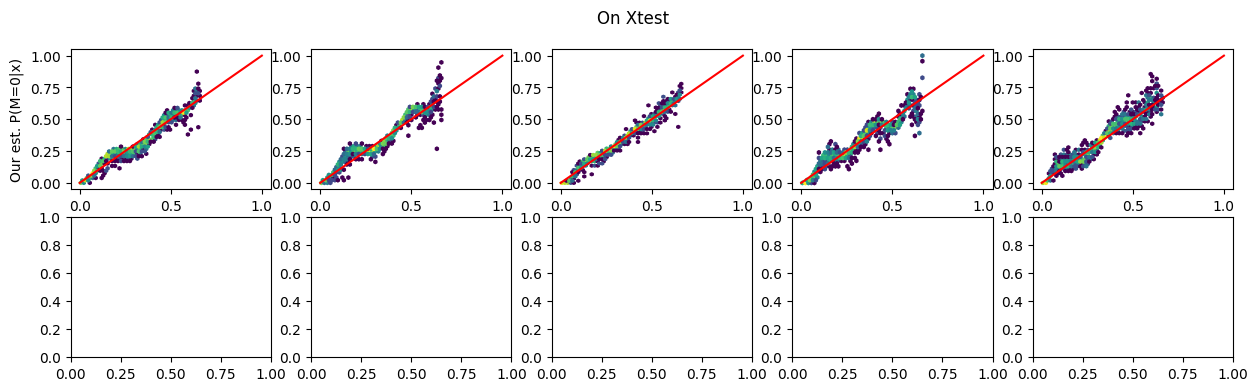

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 4))
plot_true_vs_est(axes[0], p0_true_test[:5], p0_est_test[:5], 'Our est. P(M=0|x)')
#plot_true_vs_est(axes[1], p0_true_test, p0_nmmipw_test, 'Their est. P(M=0|x)')
fig.suptitle("On Xtest")

Text(0.5, 0.98, 'On Xtrain')

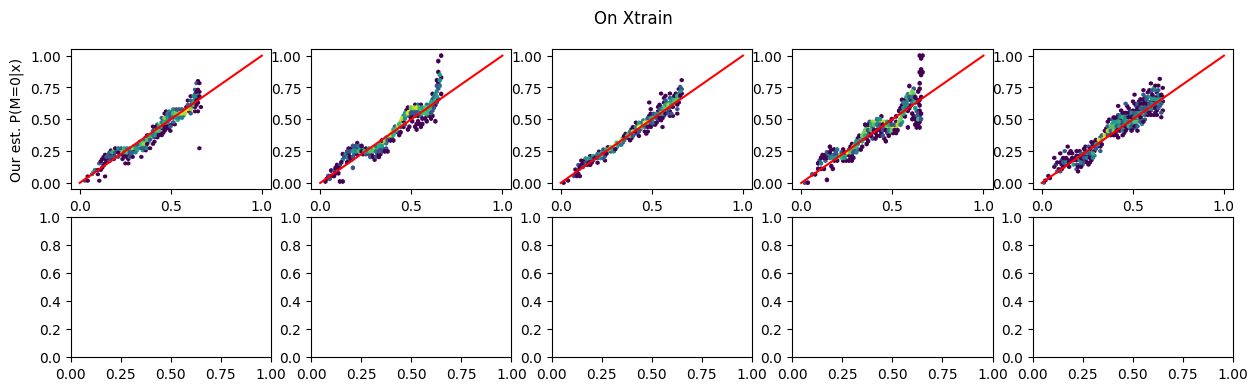

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 4))
plot_true_vs_est(axes[0], p0_true_train[:5], p0_est_train[:5], 'Our est. P(M=0|x)')
#plot_true_vs_est(axes[1], p0_true_train, p0_nmmipw_train, 'Their est. P(M=0|x)')
fig.suptitle("On Xtrain")

In [ ]:
#fig, axes = plt.subplots(2, 5, figsize=(15, 4))
#for ax, p0_true, p0_est in zip(axes[0], p0_true_test[:5], p0_est_test[:5]):    
#    ax.hexbin(1/p0_true, 1/p0_est, gridsize=40, bins='log')
#    ax.plot([0,150],[0,150],'r')
#    ax.set_xlabel('True 1/P(M=0|x)')
#axes[0,0].set_ylabel('Our est. 1/P(M=0|x)')

#for ax, p0_true, p0_est in zip(axes[1], p0_true_test[:5], p0_nmmipw_test[:5]):    
#    ax.hexbin(1/p0_true, 1/p0_est, gridsize=40, bins='log')
#    ax.plot([0,150],[0,150],'r')
#    ax.set_xlabel('True 1/P(M=0|x)')
#axes[1,0].set_ylabel('Their est. 1/P(M=0|x)')

In [ ]:
#plot_dict = {'our MSE': [mean_squared_error(p0_true, p0_est) for p0_true, p0_est in zip(p0_true_test, p0_est_test)], 
#             'their MSE': [mean_squared_error(p0_true, p0_est) for p0_true, p0_est in zip(p0_true_test, p0_nmmipw_test)]}
#fig, ax = plt.subplots()
#ax.boxplot(plot_dict.values())
#ax.set_xticklabels(plot_dict.keys())

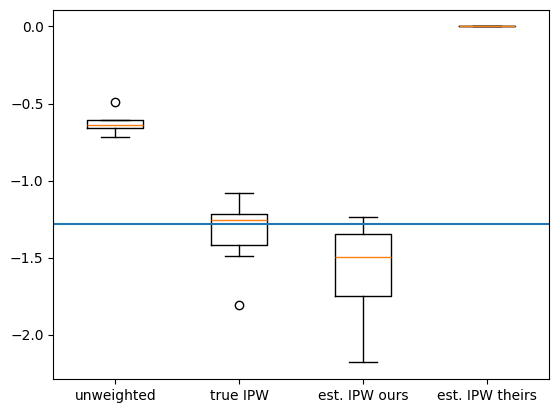

In [ ]:
plot_dict = {'unweighted': quantile_unweighted, 
             'true IPW': quantile_p0_true, 
             'est. IPW ours': quantile_p0_est, 
             'est. IPW theirs': quantile_p0_nmmipw}
fig, ax = plt.subplots()
ax.boxplot(plot_dict.values())
ax.set_xticklabels(plot_dict.keys())
ax.axhline(-1.282)